# BKT transition from 1/ε — 11.8 scan (N = 50)

**Data.** `Downloads/11.8.tar`, unpacked to `Downloads/11.8_data/runs` (377 jobs, 7,436 runs, all complete, one replicate, random non-overlapping starts).
N = 50; 11 densities ρ* = 0.001 … 0.1 (log-spaced); **T\* = 0.05 … 0.30 in steps of 0.01; E0\* = 0 … 0.5 in steps of 0.02** (finer than the 9.21 scan, which had 0.02 / 0.05).
Runs at E0\* > 0: 20k burn-in + 400k sweeps, 2,000 samples. Runs at E0\* = 0 are shorter: 5k + 10k sweeps, 1,000 samples.

**Pipeline.** `compute_dielectric.py` → `Results/runs_11p8.csv` (one row per run) → `bkt_criterion.py` → `Results/states_labelled.csv`, `Results/bkt_lines.csv` → `bkt_plots.py` (figures).

**Convention** (same as 9.21): S_QQ, S_NN carry **no 1/N**; L = 1; κ = 1/T\*.

$$\frac{1}{\varepsilon(k)} = 1 - \frac{\kappa\, S_{QQ}(m^2)}{2\pi m^2},\qquad k = 2\pi\sqrt{m^2},\qquad S_{QQ}(m^2) = \langle |Q_m|^2\rangle .$$

The BKT test uses the smallest shell, m² = 1. The stored |Q_m|² was checked against a direct recomputation from the coordinates and agrees exactly.

## The criterion

The Nelson–Kosterlitz universal jump: in the dielectric (bound-pair) phase $K_R = 1/(\varepsilon T^*) \ge 4$; at $T_{BKT}$ it jumps to 0. So the order parameter is

$$d \;=\; \frac{1}{\varepsilon(k_{\min})} - 4T^* ,\qquad \sigma = \text{block error of } 1/\varepsilon \ (20 \text{ blocks}).$$

**Step 1 — which states count (valid).** *Homogeneous* states only: in none of the run's 100 snapshots does one cluster (bond: r < 1.5σ, periodic) hold N/2 or more particles. A droplet, even part-time, is excluded, because a crossing inside a droplet is not pair unbinding. (A half-run drift check was tried and dropped: it changed 3 verdicts and never moved T_BKT; see section 4.)

**Step 2 — label each valid state.** **D** (dielectric) if d > +2σ; **C** (conducting) if d < −2σ; **M** (on the line within noise) otherwise.

**Step 3 — verdict for each line at fixed (ρ\*, E0\*).** The line **has a BKT transition** if, going up in T\*, the D/C labels of its valid states form one block of D followed by one block of C (D…D C…C; M allowed anywhere), and no excluded state sits inside the bracket [last D, first C].
 $T_{BKT}$ = zero of a weighted straight-line fit of d(T\*) over the bracket (the error bar is statistical only; the bracket is 0.01–0.02 wide).

Otherwise the verdict is one of: `no_dielectric` (valid states exist but none is D: the gas condenses before pairs bind), `all_droplet` (no valid state), `no_conductor`, `non_monotone` or `droplet_in_bracket` (ambiguous, not counted). In this scan only the first two occur.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import bkt_criterion as B
import bkt_plots as P
pd.set_option('display.width', 200)

runs = pd.read_csv('Results/runs_11p8.csv')
st = B.label_states(runs)
li = B.classify_all(st)
st.to_csv('Results/states_labelled.csv', index=False)
li.to_csv('Results/bkt_lines.csv', index=False)
print(len(runs), 'runs;', len(li), 'lines (rho*, E0*)')
print(st.label.value_counts().to_string())
print(li.verdict.value_counts().to_string())

7436 runs; 286 lines (rho*, E0*)
label
drop    4814
C       1671
D        901
M         50
verdict
BKT              102
no_dielectric     93
all_droplet       91


## Data quality

- Error bars are small. Among valid states the median σ(1/ε) is 0.006 (99% below 0.025), and the effective number of independent samples is at least 72 (median about 2,000; E0\* = 0 runs median about 600). The slow runs (fewer than 50 effective samples) are all droplets, which are excluded anyway.
- The droplet test is not borderline: the mean largest-cluster fraction is almost two-valued (≈ 0.05 for a pair gas, ≈ 1 for a droplet).

In [2]:
q = runs[['inv_eps_sem', 'n_eff', 'lc_frac', 'acc']].describe(percentiles=[.1, .5, .9]).T
print(q.round(4).to_string())
print('\nlargest-cluster fraction (run mean), counts per bin:')
print(pd.cut(runs.lc_frac, [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0001]).value_counts(sort=False).to_string())

              count       mean        std      min      10%        50%        90%        max
inv_eps_sem  7436.0     0.0059     0.0085   0.0001   0.0004     0.0032     0.0140     0.1753
n_eff        7436.0  1330.3266  1104.9884  19.8700  50.4429  1375.7244  2728.1772  8397.5667
lc_frac      7436.0     0.6286     0.4332   0.0402   0.0484     0.9551     1.0000     1.0000
acc          7436.0     0.0731     0.1113   0.0001   0.0003     0.0156     0.2600     0.4699

largest-cluster fraction (run mean), counts per bin:
lc_frac
(0.0, 0.1]    2258
(0.1, 0.2]     406
(0.2, 0.3]      75
(0.3, 0.4]      51
(0.4, 0.5]      52
(0.5, 0.6]      57
(0.6, 0.7]      84
(0.7, 0.8]     120
(0.8, 0.9]     241
(0.9, 1.0]    4092


## 1. Cuts: 1/ε against the 4T\* line

Filled points are valid states, hollow points are excluded droplets. Diamonds mark T_BKT where the line passes the criterion.
At ρ\* = 0.0251 and E0\* = 0.2 the curve crosses 4T\* only inside the droplet region (hollow points), so there is no BKT on that line.

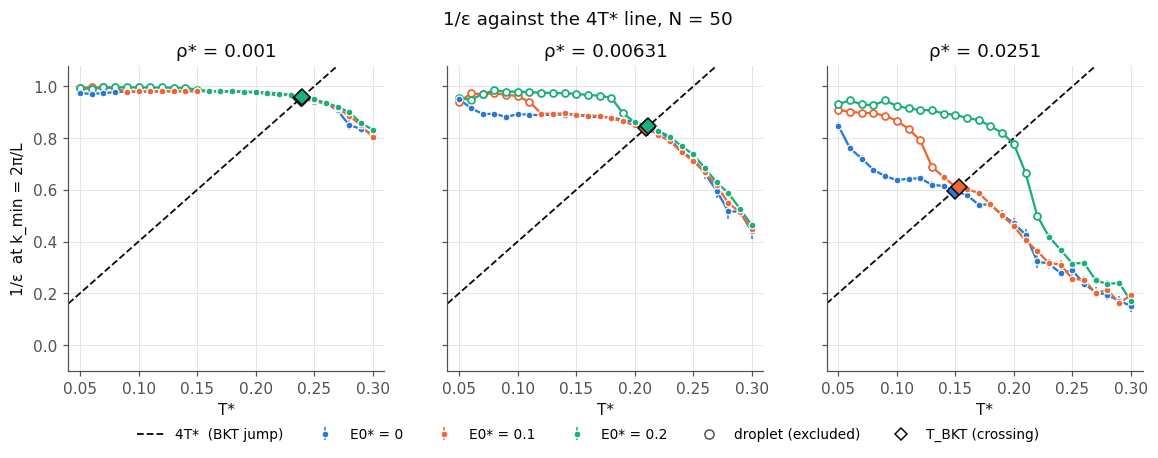

In [3]:
P.fig_cuts(st, li); plt.show()

## 2. Phase regions

Purple = dielectric gas (insulator), gray = plasma (conductor), light blue = liquid (droplet); red = T_BKT on the lines that pass. The liquid boundary sits half a grid cell above the highest droplet state of each E0\* column; the dielectric region lies between it and T_BKT, and the plasma above. Where a BKT line ends, the dielectric region is closed halfway to the next E0\* point (dashed red, not measured).
The BKT line **ends where the liquid region reaches it**: past that E0\*, the plasma condenses straight into a droplet and never becomes a dielectric gas.

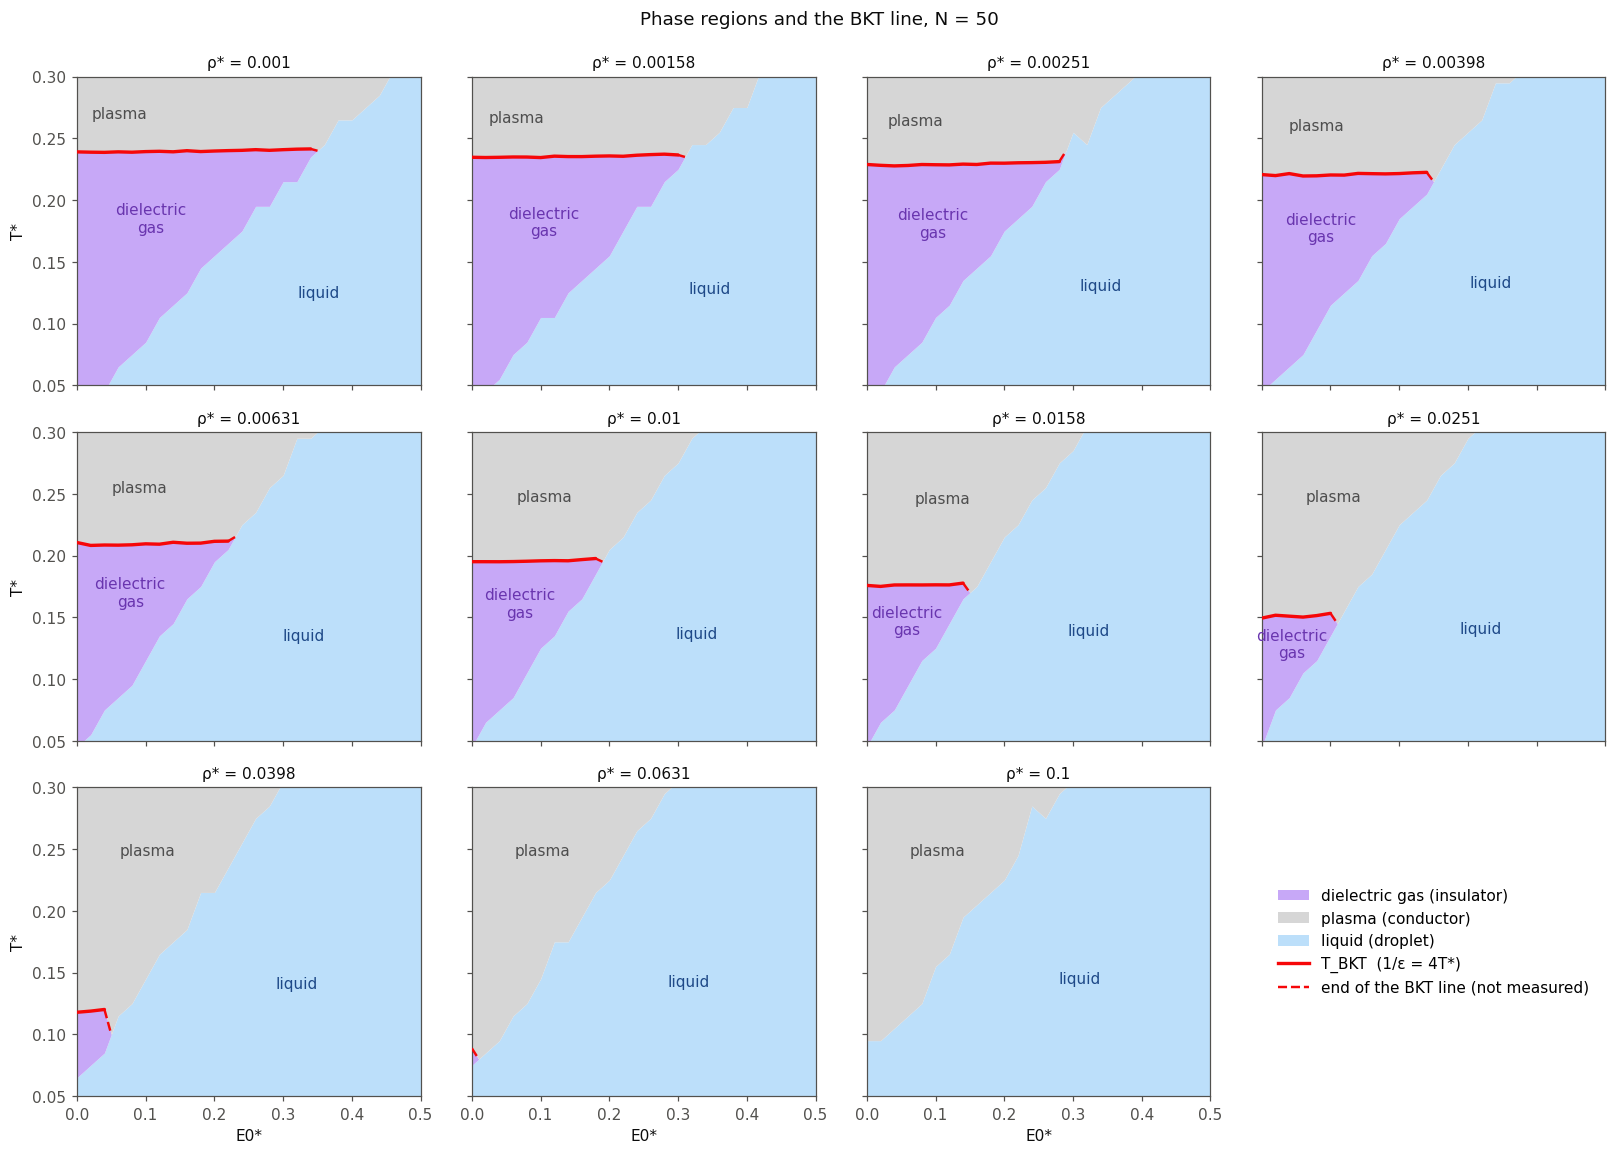

In [4]:
P.fig_maps(st, li); plt.show()

## 3. The BKT line

Left: T_BKT(E0\*) at each density. Right: the pure Coulomb gas (E0\* = 0) against the earlier N = 50 crossings from `9.6_Summary`.

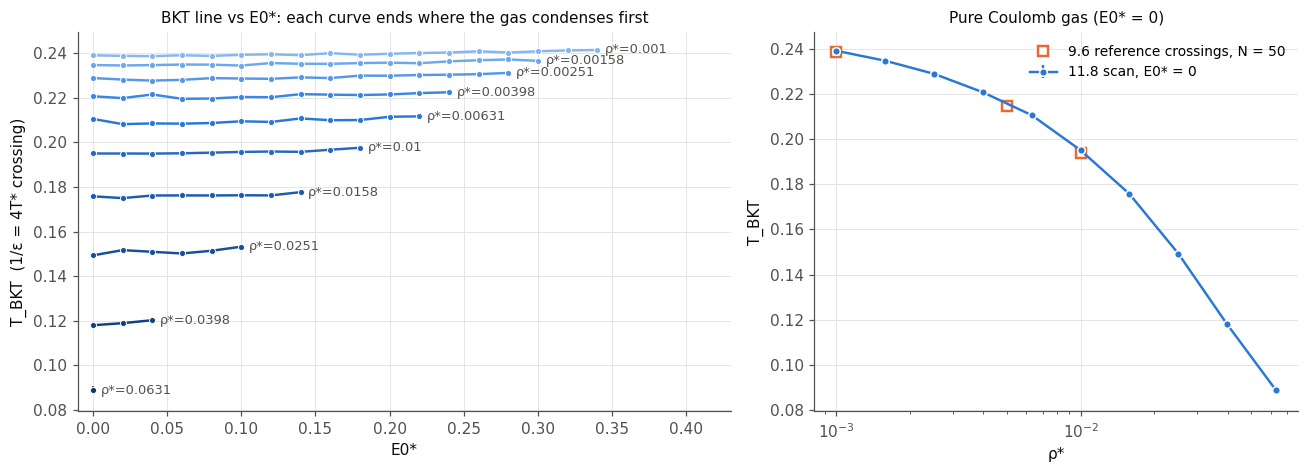

In [5]:
P.fig_lines(li); plt.show()

In [6]:
b = li[li.verdict == 'BKT']
def summary(g):
    gb = g[g.verdict == 'BKT'].sort_values('E0_star')
    after = g[(g.E0_star > gb.E0_star.max()) & (g.verdict != 'BKT')].E0_star.min() if len(gb) else np.nan
    e0 = gb[np.isclose(gb.E0_star, 0)]
    return pd.Series({
        'T_BKT(E0*=0)': e0.T_BKT.iloc[0] if len(e0) else np.nan,
        'BKT for E0* <=': gb.E0_star.max() if len(gb) else np.nan,
        'no dielectric gas from E0* =': after,
        'T_BKT min': gb.T_BKT.min(), 'T_BKT max': gb.T_BKT.max(), 'BKT lines': len(gb)})
tab = li.groupby('rho_star')[['E0_star', 'verdict', 'T_BKT']].apply(summary)
tab.to_csv('Results/bkt_summary_by_density.csv')
tab.round(4)

,T_BKT(E0*=0),BKT for E0* <=,no dielectric gas from E0* =,T_BKT min,T_BKT max,BKT lines
rho_star,,,,,,
0.00100,0.2391,0.34,0.36,0.2387,0.2415,18.0
0.00158,0.2347,0.30,0.32,0.2345,0.2372,16.0
0.00251,0.2289,0.28,0.30,0.2277,0.2312,15.0
0.00398,0.2207,0.24,0.26,0.2196,0.2225,13.0
0.00631,0.2106,0.22,0.24,0.2082,0.2117,12.0
0.01000,0.1950,0.18,0.20,0.1950,0.1976,10.0
0.01580,0.1758,0.14,0.16,0.1750,0.1777,8.0
0.02510,0.1493,0.10,0.12,0.1493,0.1532,6.0
0.03980,0.1180,0.04,0.06,0.1180,0.1202,3.0


## 4. Is the result sensitive to the thresholds?

Each row changes one setting and compares with the baseline (2σ, droplet = any snapshot ≥ N/2, no drift check).

In [7]:
base = li.set_index(['rho_star', 'E0_star'])
def variant(z=2.0, droplet='max', drift_z=None):
    d = runs.copy()
    if droplet == 'mean':
        d['lc_frac_max'] = d['lc_frac']        # droplet only if the run-mean cluster >= N/2
    return B.classify_all(B.label_states(d, z=z, drift_z=drift_z)).set_index(['rho_star', 'E0_star'])
rows = []
for name, kw in [('labels at 3σ', dict(z=3.0)), ('labels at 1.5σ', dict(z=1.5)),
                 ('droplet = run mean ≥ N/2', dict(droplet='mean')), ('with drift check (3σ)', dict(drift_z=3.0))]:
    L = variant(**kw)
    both = (base.verdict == 'BKT') & (L.verdict == 'BKT')
    rows.append(dict(variant=name, BKT_lines=int((L.verdict == 'BKT').sum()),
                     verdict_changed=int(((base.verdict == 'BKT') != (L.verdict == 'BKT')).sum()),
                     max_abs_dT=(L.T_BKT - base.T_BKT)[both].abs().max()))
pd.DataFrame(rows).round(4)

,variant,BKT_lines,verdict_changed,max_abs_dT
0,labels at 3σ,99,3,0.0012
1,labels at 1.5σ,102,0,0.0028
2,droplet = run mean ≥ N/2,120,18,0.0000
3,with drift check (3σ),99,3,0.0000


Reading the table:
- The significance level (1.5σ, 2σ or 3σ) moves T_BKT by at most ~0.003 and changes at most 3 verdicts.
- Adding the half-run drift check (3σ) removes 3 lines and never moves T_BKT, so it is left out.
- The droplet rule matters. With the looser "run-mean" rule, 18 more lines pass, all at the end of a BKT line next to the droplet region. Their T_BKT climbs steeply (e.g. ρ\* = 0.0251: 0.153 → 0.177). In every one of them the single D state has snapshots where a droplet holds 80–90% of the particles, and S_NN(k_min)/N is 20–30 instead of ~2–3. Those runs move between gas and droplet, so they are excluded.

## 5. What this does and does not show

- **BKT exists** at every density from ρ\* = 0.001 to 0.063, for E0\* up to an end point that falls with density: 0.34 at ρ\* = 0.001, 0.18 at 0.01, 0.10 at 0.0251, and only E0\* = 0 at 0.063. At ρ\* = 0.1 there is no BKT on any line.
- **ρ\* = 0.063 is marginal.** Its one BKT line (E0\* = 0, T_BKT ≈ 0.089) has a single D state, and it drops out at 3σ. Treat the end of the BKT line as lying between ρ\* = 0.04 and 0.1.
- **T_BKT barely depends on E0\***. Along each line it changes by ≤ 0.004, much less than its change with density. The short-range attraction does not move the pair-unbinding temperature; it decides where condensation cuts the line off.
- **E0\* = 0 agrees with the earlier work**: 0.2391 vs 0.2387 at ρ\* = 0.001, and 0.1950 vs 0.1939 at ρ\* = 0.01.
- **Finite size.** Everything is at N = 50, so these are N = 50 crossing temperatures. A single N cannot show that the jump becomes a true discontinuity; that needs the N = 100 / 200 data and a finite-size fit.
- 1/ε is taken at k_min only (finite-k proxy for k → 0), as in Orkoulas & Panagiotopoulos.